# Figure3 Interactions

Reproduces panels used in the main manuscript. Generated files are written to `logs/scripts/figure3_interactions/`.


In [1]:
import os, sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "scripts" else Path.cwd()
sys.path.insert(0, str(ROOT))
os.chdir(ROOT)


In [2]:
import re
import sys
import json
import yaml
import shlex
import random
import dotenv
import signal
import logging
import datetime
import nd2py as nd
import numpy as np
import pandas as pd
from pathlib import Path
from datetime import datetime
from socket import gethostname
from argparse import Namespace
from argparse import ArgumentParser
from nd2py.utils import init_logger
from setproctitle import setproctitle
from src.utils import add_negation_flags, tag2ansi, log_exception
from src.core import Triplet, Individual
from src.assistant import Assistant
from src.ai_scientist import AIScientist
from src.ai_scientist_parallel import AIScientistParallel
from src.utils import wrap_ansi

import warnings
# warnings.simplefilter('error', RuntimeWarning)
warnings.filterwarnings("ignore", category=UserWarning, module="nd2py")

dotenv.load_dotenv()
_logger = logging.getLogger('src')

args = Namespace(**json.load(open('data/cache/default_args.json', 'r')))
args.save_dir = './logs/scripts'
args.exp_name = 'figure3_interactions'
args.train_period = ['all', 'all']
args.test_period = ['all', 'all']
args.a_skill_after_2004 = 0.0

## Build Save Path
if args.exp_name is None:
    now = datetime.now()
    date = now.strftime("%Y%m%d")
    curr = now.strftime("%H%M%S")
    host = gethostname()
    exp_name = f'{date}_{args.name}_{curr}_{host}'
    exp_name = re.compile(r'[ <>:"/\\|?*\x00-\x1f]').sub('_', exp_name.strip())
    exp_name = exp_name or 'unnamed'
    exp_name = exp_name[:255] # Max filename length on most filesystems
    args.exp_name = exp_name
save_path = Path(args.save_dir) / args.exp_name
if not save_path.exists():
    save_path.mkdir(parents=True, exist_ok=True)
else:
    _logger.warning(f"Save path {save_path} already exists.")
args.save_path = str(save_path)

## Set Random State
if args.random_state is None:
    args.random_state = random.randint(0, 2**31 - 1)
## Set Command
args.command = ' '.join(map(shlex.quote, [sys.executable, *sys.argv]))

args.debug = True

## Init Logger
init_logger(
    "src", 
    exp_name=args.exp_name, 
    log_file=save_path / "info.log", 
    info_level='debug' if args.debug else 'info',
    show_lineno_for_all_levels=args.debug,
)
nd2py_logger = logging.getLogger("nd2py")
nd2py_logger.setLevel(_logger.level)
nd2py_logger.handlers = _logger.handlers.copy()

## Save Args
args_path = save_path / "args.json"
if args_path.exists():
    i = 1
    while args_path.with_suffix(f".json.{i}").exists(): i += 1
    args_path.rename(args_path.with_suffix(f".json.{i}"))
    _logger.warning(f"args.json already exists, backup to args.json.{i}")
_logger.note(f"Args: {args}")
with open(args_path, "w") as f:
    json.dump(vars(args), f, indent=4, ensure_ascii=False)

# Start the main process
setproctitle(f"{args.exp_name}@ZihanYu")

## Load Assistant
assistant = Assistant(args)
## Load Data
# 加载变量
variables = assistant.load_variables()
# 加载数据
df_all = assistant.load_data(normalize_co2=False)
# 划分数据
if True:
    train_start, train_end = args.train_period
    test_start, test_end = args.test_period
    train_start = pd.Period(train_start, freq='M') if train_start != 'all' else df_all.index[0]
    train_end = pd.Period(train_end, freq='M') if train_end != 'all' else df_all.index[-1]
    test_start = pd.Period(test_start, freq='M') if test_start != 'all' else df_all.index[0]
    test_end = pd.Period(test_end, freq='M') if test_end != 'all' else df_all.index[-1]
    df_train = df_all.loc[train_start:train_end]
    df_test = df_all.loc[test_start:test_end]
elif False:
    df_train = df_all.loc[pd.Period(year=1979, month=1, freq='M'):pd.Period(year=2022, month=12, freq='M')]
    df_test = df_all.loc[pd.Period(year=1979, month=1, freq='M'):pd.Period(year=2022, month=12, freq='M')]
else:
    df_train = df_all.loc[pd.Period(year=1979, month=1, freq='M'):pd.Period(year=1999, month=12, freq='M')]
    df_test = df_all.loc[pd.Period(year=2000, month=1, freq='M'):pd.Period(year=2022, month=12, freq='M')]
# 准备拓扑
edge_list, num_nodes = assistant.load_topology()
# 打印日志
_logger.info(
    f"Data loaded: {len(df_all)} samples, "
    f"where {len(df_train)}({len(df_train)/len(df_all):.2%}) "
    f"from {df_train.index[0]} to {df_train.index[-1]} for training, "
    f"and {len(df_test)}({len(df_test)/len(df_all):.2%}) "
    f"from {df_test.index[0]} to {df_test.index[-1]} for testing."
)
_logger.info(
    f"Variables: " + ", ".join(f'{var_name}({len(sub_df)})' for var_name, sub_df in df_all.T.groupby(level=0)) + "."
)
## Load Seed Individuals
seed_individuals = assistant.load_seed_individuals()

## Initialize Runner
Runner = AIScientistParallel if args.parallel else AIScientist
kwargs = dict(
    args=args,
    assistant=assistant,
    variables=variables,
    binary=[
        getattr(nd, name) for name in args.binary
        # nd.Add, nd.Sub, nd.Mul, nd.Div
    ],
    unary=[
        getattr(nd, name) for name in args.unary
        # nd.Sin, nd.Cos,
        # nd.Exp, nd.LogAbs,
        # nd.Sigmoid, nd.Tanh,
        # nd.Pow2, nd.Pow3, nd.SqrtAbs,
        # nd.Aggr, nd.Readout, nd.Sour, nd.Targ,
    ],
    edge_list=edge_list,
    num_nodes=num_nodes,
    seed_individuals=seed_individuals,
)
_logger.note(f"Initializing Runner with args: {kwargs}")
est = Runner(**kwargs)
# Set Clip Bounds
est.evaluator.simulator.set_clip_bounds(df_all, clip_factor=args.clip_factor)

Save path logs/scripts/figure3_interactions already exists.
[figure3_interactions|src|W|Oct15 11:25:24|0:00:00.001601] (../../../../../../tmp/ipykernel_2944876/1049127511.py:86) args.json already exists, backup to args.json.10
[figure3_interactions|src|N|Oct15 11:25:24|0:00:00.002835] (venv/lib/python3.12/site-packages/nd2py/utils/logger.py:62) Args: Namespace(name='Reduce_320_230_368', setting='only_co2', exp_name='figure3_interactions', llm_model=None, llm_provider=None, seed_individuals=['co2_320_230_368'], load_seed_individuals=[], use_seed_individuals_only=True, num_workers=24, parallel=True, timeout=240, population_size=200, n_iter=300, programs_per_prompt=2, generate_per_prompt=8, expire_iter=1, keep_best=False, random_state=1581316702, score_func='tanh', a_rmse=0.0, a_trajrmse=0.0, a_skill_cv_sum=0.0, a_skill_cv_sum_inner=0.0, a_skill_cv_mean=0.0, a_ENSO_skill_cv=1.0, a_Total_skill_cv=10.0, a_skill_sum_inner=0.0, a_skill_sum=0.0, a_skill_mean=0.0, a_ENSO_skill=0.0, a_IOB_skill=

In [3]:
args.a_rmse = 0.0
args.a_trajrmse = 0.0
args.a_skill_cv_sum = 0.0
args.a_skill_cv_sum_inner = 0.0
args.a_skill_cv_mean = 0.0
args.a_ENSO_skill_cv = 1.0
args.a_ATL3_skill_cv = 1.0
args.a_SASD_skill_cv = 1.0
args.a_Total_skill_cv = 10.0
args.a_skill_sum_inner = 0.0
args.a_skill_sum = 0.0
args.a_skill_mean = 0.0
args.a_ENSO_skill = 0.0
args.a_IOB_skill = 0.0
args.a_SASD_skill = 0.0
args.a_Total_skill = 0.0
args.a_skill_after_2004 = 1.0
args.a_length = 1.0
args.a_params = 0.0
args.a_std = 0.25
args.a_skewness = 0.25
args.a_spectrum = 0.25
args.a_leadlag = 0.25
args.a_forecast = 0.0
args.a_contain_co2 = 0.0
args.max_month = 40
args.a_correlation_auc_sum = 0.0
args.a_correlation_auc_cv_sum = 0.0

args.damp = 1e-1
args.atol = 1e-6
args.btol = 1e-6
args.iter_lim = None

In [4]:
baseline_indiv = assistant.load_baseline_indiv()

def evaluate6(indiv, df_test, df_train=None):

    if df_train is not None:
        if indiv.fitness is not None:
            _logger.warning("Refitting dynamics for individual during set_fitness.")
        dynamics = est.evaluator.assistant.triplet_to_dynamics(indiv.triplet)
        dynamics, mse = est.evaluator.fitter.fit_parameters(dynamics, df_train)
        indiv.dynamics = dynamics
        if not np.isfinite(mse):
            indiv.fitness = -np.inf
            indiv.detail = {"error": f"Invalid MSE {mse}"}
            return

    dt = df_test['t'].values[1, 0] - df_test['t'].values[0, 0]
    ## 无噪声预测
    PREDICTION = est.evaluator.simulator.get_simulation_with_forcing(
        indiv.dynamics, df_test[['x', 'h', 't']], dt, df_test.drop(columns=['x', 'h', 't'], level=0),
        max_month=est.evaluator.args.max_month, tqdm_desc=None
    )
    return PREDICTION

In [5]:
import warnings

# 专门屏蔽 QuadContourSet 的光栅化警告
warnings.filterwarnings(
    "ignore", 
    message="Rasterization of '<matplotlib.contour.QuadContourSet", 
    category=UserWarning
)

In [6]:
baseline_indiv = assistant.load_baseline_indiv()

def evaluate3(indiv, df_test, df_train=None):
    if df_train is None:
        df_train = df_test

    # Set Ground Truth Results
    _logger.info(f"Calculating ground truth result on test data...")
    est.evaluator.set_ground_truth_result(df_test)
    # Set XRO Baseline Results
    _logger.info(f"Evaluating XRO on test data as baseline...")
    baseline_dynamics = assistant.triplet_to_dynamics(baseline_indiv.triplet)
    baseline_indiv.dynamics, mse = est.evaluator.fitter.fit_parameters(baseline_dynamics, df_train, nonlinear=True)
    est.evaluator.set_baseline_result(baseline_indiv.dynamics, df_test, use_tqdm=False)
    baseline_indiv.fitness, baseline_indiv.detail = est.evaluator.get_fitness(est.evaluator.baseline_result)
    baseline_log = est.get_log_for_indiv(baseline_indiv)
    if False:
        _logger.info(tag2ansi(f"[green]Evaluate XRO on Test Data from {df_test.index[0]} to {df_test.index[-1]} (parameters are fitted on Train Data from {df_train.index[0]} to {df_train.index[-1]})[reset]"))
        _logger.info(tag2ansi("\n".join(f"[#66CCFF]{k.strip('\n')}[reset]={wrap_ansi(tag2ansi(v), 150).strip('\n')}" for k, v in baseline_log.items())))

    est.evaluator.set_fitness(indiv, df_test, df_fit=df_train, use_tqdm=False)
    log = est.get_log_for_indiv(indiv)
    _logger.info(tag2ansi(f"[green]Evaluate on Test Data from {df_test.index[0]} to {df_test.index[-1]} (parameters are fitted on Train Data from {df_train.index[0]} to {df_train.index[-1]})[reset]"))
    _logger.info(tag2ansi("\n".join(f"[#66CCFF]{k.strip('\n')}[reset]={wrap_ansi(tag2ansi(v), 150).strip('\n')}" for k, v in log.items())))


# df_all = assistant.load_data(normalize_co2=True)
df_all = assistant.load_data(normalize_co2=False)

triplet = assistant.program_to_triplet("""
def get_equations(t, x, h, u_co2, mode, nl_params):
    coeff = 1 + cos(t) + sin(t) + sin(0.50 * t) + sin(2 * t)
    dx_dt = x + mode['ENSO'] * h + log(u_co2) + aggr( sour(x) + tanh(0.70 * sour(h)) * (1.00 + 1.20 * targ(x) + 1.10 * readout(x)) )
    dh_dt = h + readout(x) ** 2               + aggr( sour(x) + tanh(2.00 * sour(h)) * (0.65 + 0.60 * targ(h) + 0.10 * readout(x)) )
    return coeff, dx_dt, dh_dt
""")
indiv = Individual(
    uuid=None,
    n_iter=None,
    source=None,
    parents=[],
    program=assistant.triplet_to_program(triplet),
    triplet=triplet,
    dynamics=assistant.triplet_to_dynamics(triplet),
)

args.a_skill_after_2004 = 0.0
args.use_nfold_cv = False
args.use_l3yo_cv = False
evaluate3(indiv, df_all.loc['1979-01':'2024-12'], df_all.loc['1979-01':'2024-12'])

[figure3_interactions|data_loader|D|Oct15 11:25:25|0:00:00.184016] (src/assistant/data_loader.py:55) Detrending ENSO SST with coefficients: [-7.14225957e-07  3.27857303e-04  8.16754329e-02]
[figure3_interactions|data_loader|D|Oct15 11:25:25|0:00:00.185702] (src/assistant/data_loader.py:55) Detrending NPMM SST with coefficients: [ 5.23786876e-06 -5.07198219e-03  1.14418764e+00]
[figure3_interactions|data_loader|D|Oct15 11:25:25|0:00:00.187165] (src/assistant/data_loader.py:55) Detrending SPMM SST with coefficients: [-6.20970905e-07 -3.72185672e-04  3.92080518e-01]
[figure3_interactions|data_loader|D|Oct15 11:25:25|0:00:00.188975] (src/assistant/data_loader.py:55) Detrending IOB SST with coefficients: [ 1.84648014e-06 -1.01057274e-03  8.39776510e-02]
[figure3_interactions|data_loader|D|Oct15 11:25:25|0:00:00.190362] (src/assistant/data_loader.py:55) Detrending IOD SST with coefficients: [-1.41512104e-06  1.72745765e-03 -5.17341840e-01]
[figure3_interactions|data_loader|D|Oct15 11:25:25|0

[figure3_interactions|src|I|Oct15 11:25:45|0:00:20.803822] (../../../../../../tmp/ipykernel_2944876/3281052465.py:23) Evaluate on Test Data from 1979-01 to 2024-12 (parameters are fitted on Train Data from 1979-01 to 2024-12)
[figure3_interactions|src|I|Oct15 11:25:45|0:00:20.806117] (../../../../../../tmp/ipykernel_2944876/3281052465.py:24) Info=None from None() at Iter None
        Fitness=4.176335
        Skills=x_ENSO=32 month; x_NPMM=17 month; x_SPMM=5 month; x_IOB=29 month; x_IOD=13 month; x_SIOD=19 month; x_TNA=10 month; x_ATL3=5 month; x_SASD=5 month; h_E
        NSO=24 month; h_NPMM=23 month; h_SPMM=20 month; h_IOB=33 month; h_IOD=24 month; h_SIOD=29 month; h_TNA=15 month; h_ATL3=6 month; h_SASD=15 month;Total
         SST=135 month;Total Z20=189 month;Total=324 month
        Skills%=x_ENSO=+68.42%;x_NPMM=-5.56%;x_SPMM=+0.00%;x_IOB=+26.09%;x_IOD=+116.67%;x_SIOD=+18.75%;x_TNA=+0.00%;x_ATL3=+25.00%;x_SASD=-28.57%;h_ENSO=+41.18%;h_NPM
        M=+21.05%;h_SPMM=+25.00%;h_IOB=+106.2

[某个 Local Mode] 的 {SST, OHC} 受到 [某个 RemoteMode] 的 {SST, OHC} 的直接影响，并对 [另一个 Local Mode] 的 {SST, OHC} 产生间接影响

# 移除所有模态对的 Remote OHC / SST，看各个模态怎么变
移除 “所有 Local Mode” 的 {SST, OHC} 受到 “所有 Remote Mode” 的 {SST, OHC} 的直接影响，检查 [各个 Local Mode] 的 {SST, OHC} 受到的间接影响

In [7]:
# df_all = assistant.load_data(normalize_co2=True)
df_all = assistant.load_data(normalize_co2=False)

triplet = assistant.program_to_triplet("""
def get_equations(t, x, h, u_co2, mode, nl_params):
    coeff = 1 + cos(t) + sin(t) + sin(0.50 * t) + sin(2 * t)
    dx_dt = Variable('damping_flag') * x + \
            Variable('recharging_flag') * mode['ENSO'] * h + \
            Variable('co2_flag') * log(u_co2) + \
            aggr( 
                Variable('sst_to_sst_flag') * sour(x) + \
                Variable('ohc_to_sst_flag') * tanh(0.70 * sour(h)) * (1.00 + 1.20 * targ(x) + 1.10 * readout(x))
            )
    dh_dt = Variable('damping_flag') * h + \
            Variable('Tbar_flag') * readout(x) ** 2 + \
            aggr(
                Variable('sst_to_ohc_flag') * sour(x) + \
                Variable('ohc_to_ohc_flag') * tanh(2.00 * sour(h)) * (0.65 + 0.60 * targ(h) + 0.10 * readout(x))
            )
    return coeff, dx_dt, dh_dt
""")
indiv = Individual(
    uuid=None,
    n_iter=None,
    source=None,
    parents=[],
    program=assistant.triplet_to_program(triplet),
    triplet=triplet,
    dynamics=assistant.triplet_to_dynamics(triplet),
)

args.max_month = 36

if True:
    df_all[('damping_flag', 'value')] = 1
    df_all[('recharging_flag', 'value')] = 1
    df_all[('co2_flag', 'value')] = 1
    df_all[('sst_to_sst_flag', 'value')] = 1
    df_all[('ohc_to_sst_flag', 'value')] = 1
    df_all[('sst_to_ohc_flag', 'value')] = 1
    df_all[('ohc_to_ohc_flag', 'value')] = 1
    df_all[('Tbar_flag', 'value')] = 1

    PREDICTION = evaluate6(indiv, df_all.loc['1979-01':'2024-12'], df_all.loc['1979-01':'2024-12'])

    df_all[('damping_flag', 'value')] = 1
    df_all[('recharging_flag', 'value')] = 1
    df_all[('co2_flag', 'value')] = 1
    df_all[('sst_to_sst_flag', 'value')] = 1
    df_all[('ohc_to_sst_flag', 'value')] = 0
    df_all[('sst_to_ohc_flag', 'value')] = 1
    df_all[('ohc_to_ohc_flag', 'value')] = 0
    df_all[('Tbar_flag', 'value')] = 1

    PREDICTION_wo_slow = evaluate6(indiv, df_all.loc['1979-01':'2024-12'], None)

    df_all[('damping_flag', 'value')] = 1
    df_all[('recharging_flag', 'value')] = 1
    df_all[('co2_flag', 'value')] = 1
    df_all[('sst_to_sst_flag', 'value')] = 1
    df_all[('ohc_to_sst_flag', 'value')] = 0
    df_all[('sst_to_ohc_flag', 'value')] = 1
    df_all[('ohc_to_ohc_flag', 'value')] = 1
    df_all[('Tbar_flag', 'value')] = 1

    PREDICTION_wo_slow_on_sst = evaluate6(indiv, df_all.loc['1979-01':'2024-12'], None)

    df_all[('damping_flag', 'value')] = 1
    df_all[('recharging_flag', 'value')] = 1
    df_all[('co2_flag', 'value')] = 1
    df_all[('sst_to_sst_flag', 'value')] = 1
    df_all[('ohc_to_sst_flag', 'value')] = 1
    df_all[('sst_to_ohc_flag', 'value')] = 1
    df_all[('ohc_to_ohc_flag', 'value')] = 0
    df_all[('Tbar_flag', 'value')] = 1

    PREDICTION_wo_slow_on_ohc = evaluate6(indiv, df_all.loc['1979-01':'2024-12'], None)

    df_all[('damping_flag', 'value')] = 1
    df_all[('recharging_flag', 'value')] = 1
    df_all[('co2_flag', 'value')] = 1
    df_all[('sst_to_sst_flag', 'value')] = 0
    df_all[('ohc_to_sst_flag', 'value')] = 1
    df_all[('sst_to_ohc_flag', 'value')] = 0
    df_all[('ohc_to_ohc_flag', 'value')] = 1
    df_all[('Tbar_flag', 'value')] = 1

    PREDICTION_wo_fast = evaluate6(indiv, df_all.loc['1979-01':'2024-12'], None)

    df_all[('damping_flag', 'value')] = 1
    df_all[('recharging_flag', 'value')] = 1
    df_all[('co2_flag', 'value')] = 1
    df_all[('sst_to_sst_flag', 'value')] = 0
    df_all[('ohc_to_sst_flag', 'value')] = 1
    df_all[('sst_to_ohc_flag', 'value')] = 1
    df_all[('ohc_to_ohc_flag', 'value')] = 1
    df_all[('Tbar_flag', 'value')] = 1

    PREDICTION_wo_fast_on_sst = evaluate6(indiv, df_all.loc['1979-01':'2024-12'], None)

    df_all[('damping_flag', 'value')] = 1
    df_all[('recharging_flag', 'value')] = 1
    df_all[('co2_flag', 'value')] = 1
    df_all[('sst_to_sst_flag', 'value')] = 1
    df_all[('ohc_to_sst_flag', 'value')] = 1
    df_all[('sst_to_ohc_flag', 'value')] = 0
    df_all[('ohc_to_ohc_flag', 'value')] = 1
    df_all[('Tbar_flag', 'value')] = 1

    PREDICTION_wo_fast_on_ohc = evaluate6(indiv, df_all.loc['1979-01':'2024-12'], None)

[figure3_interactions|data_loader|D|Oct15 11:25:45|0:00:20.827347] (src/assistant/data_loader.py:55) Detrending ENSO SST with coefficients: [-7.14225957e-07  3.27857303e-04  8.16754329e-02]
[figure3_interactions|data_loader|D|Oct15 11:25:45|0:00:20.829190] (src/assistant/data_loader.py:55) Detrending NPMM SST with coefficients: [ 5.23786876e-06 -5.07198219e-03  1.14418764e+00]
[figure3_interactions|data_loader|D|Oct15 11:25:45|0:00:20.830795] (src/assistant/data_loader.py:55) Detrending SPMM SST with coefficients: [-6.20970905e-07 -3.72185672e-04  3.92080518e-01]
[figure3_interactions|data_loader|D|Oct15 11:25:45|0:00:20.832400] (src/assistant/data_loader.py:55) Detrending IOB SST with coefficients: [ 1.84648014e-06 -1.01057274e-03  8.39776510e-02]
[figure3_interactions|data_loader|D|Oct15 11:25:45|0:00:20.834074] (src/assistant/data_loader.py:55) Detrending IOD SST with coefficients: [-1.41512104e-06  1.72745765e-03 -5.17341840e-01]
[figure3_interactions|data_loader|D|Oct15 11:25:45|0

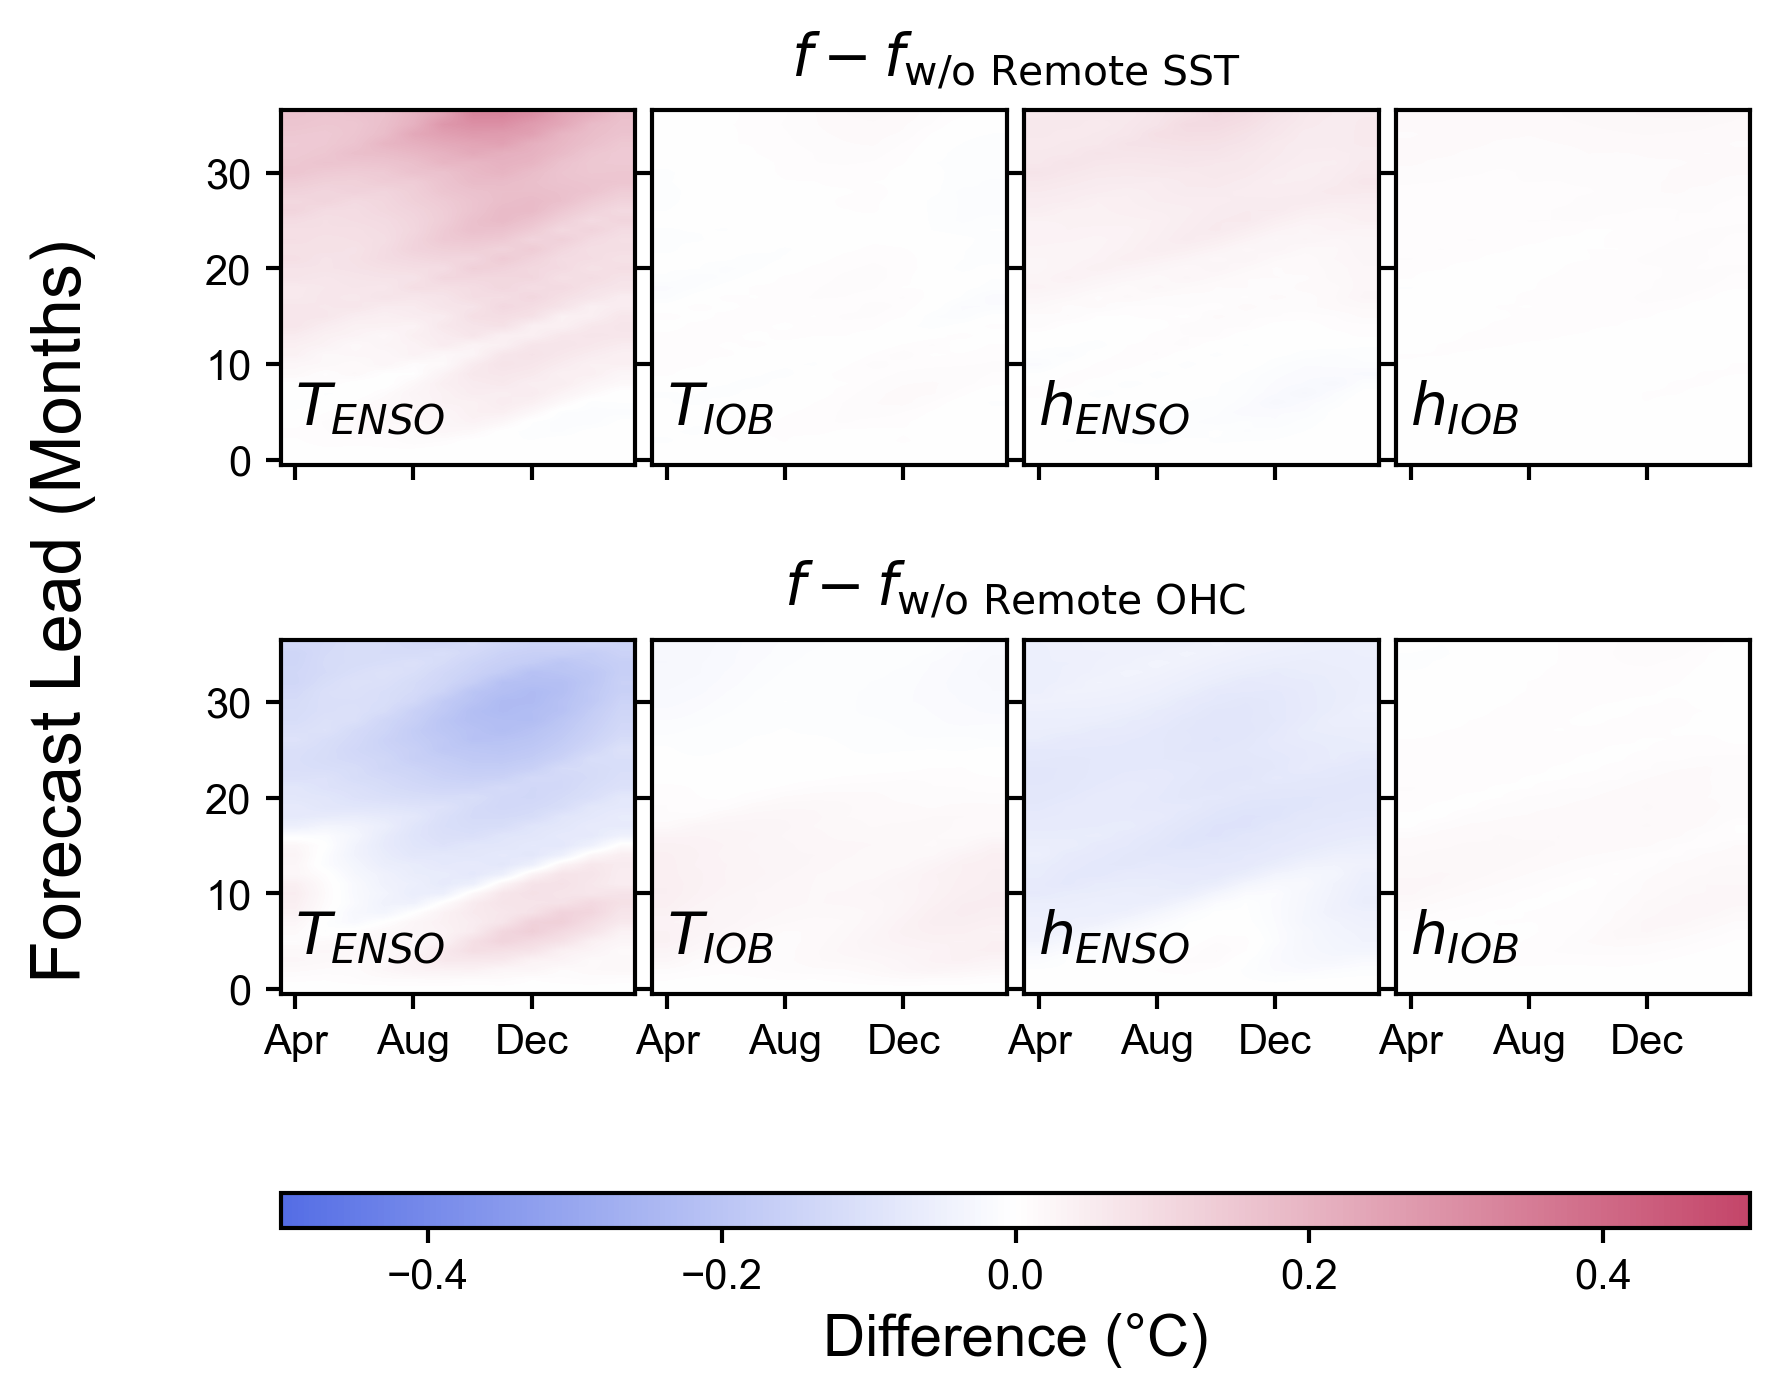

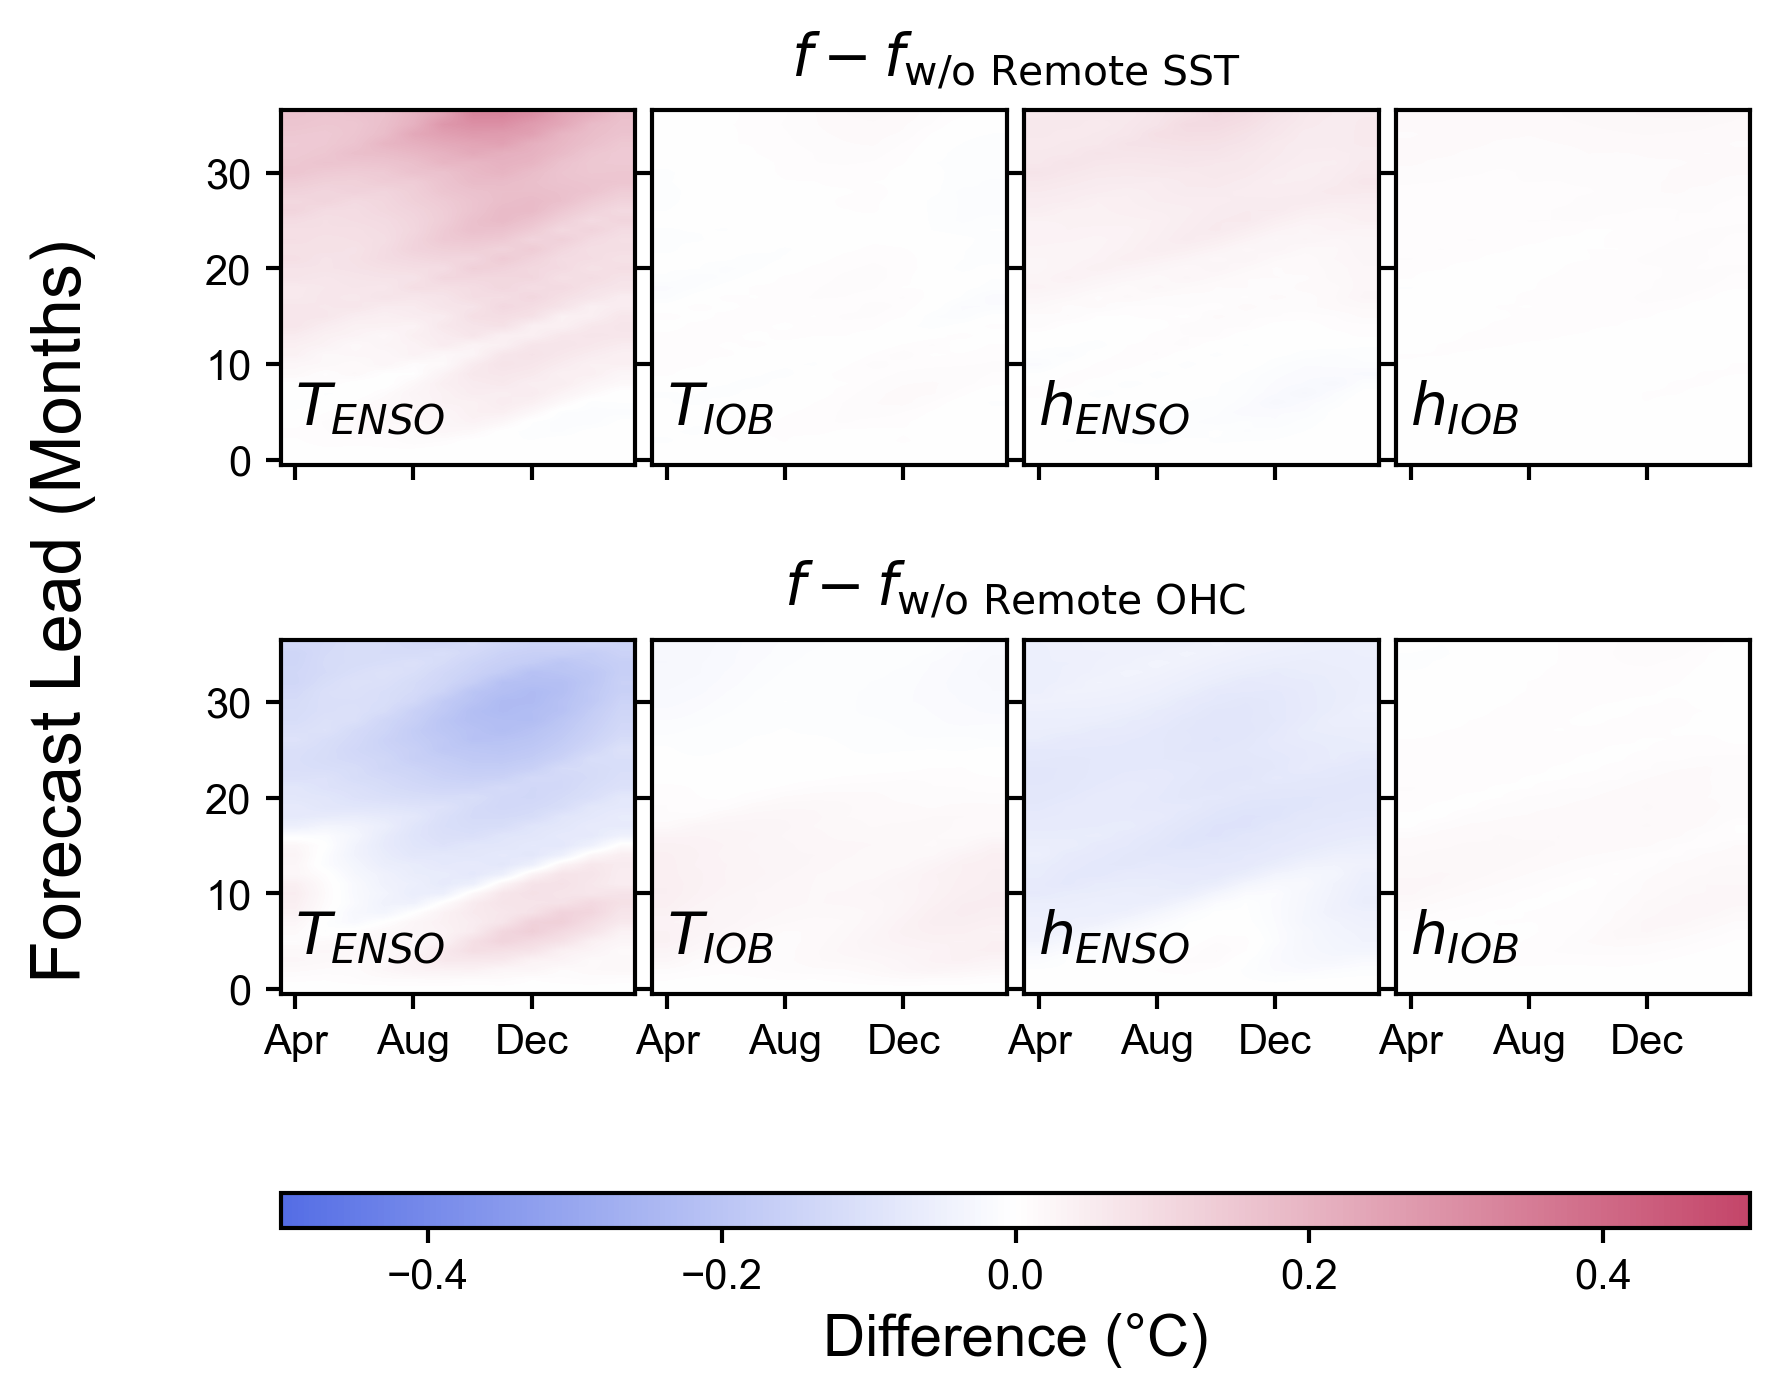

In [8]:
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from nd2py.utils.plot import get_fig

# The main-text panel uses seasonal-mean full-minus-ablated tendencies for four
# selected states, with remote-SST and remote-OHC ablations on separate rows.
row_configs = [
    (PREDICTION_wo_fast, r'$f-f_{\mathrm{w/o\ Remote\ SST}}$'),
    (PREDICTION_wo_slow, r'$f-f_{\mathrm{w/o\ Remote\ OHC}}$'),
]
panels = [('x', 'ENSO'), ('x', 'IOB'), ('h', 'ENSO'), ('h', 'IOB')]
months = ['Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec', 'Jan', 'Feb', 'Mar']
stop = PREDICTION.index.get_level_values('time') + PREDICTION.index.get_level_values('lead')
stop_month = stop.strftime('%b')
var_map = {'x': 'T', 'h': 'h'}
fi, fig, axes = get_fig(2, 4, AW=3, A_ratio=1, VS=3.0, HS=0.3,
                        LM=5, RM=5, TM=5, BM=7, dpi=300,
                        sharex=True, sharey=True, lw=1, fontsize=14)
norm = plt.Normalize(vmin=-0.5, vmax=0.5)
cmap = mcolors.LinearSegmentedColormap.from_list('custom_rdbu', ['#546de5', '#ffffff', '#c44569'])
for i, (ablated, title) in enumerate(row_configs):
    for j, (var, mode) in enumerate(panels):
        ax = axes.reshape(2, 4)[i, j]
        difference = (PREDICTION - ablated)[(var, mode)].to_frame('value').reset_index().assign(stop_month=stop_month).pivot_table(index='lead', columns='stop_month', values='value')[months]
        im = ax.imshow(difference.values, interpolation='bilinear', aspect='auto', rasterized=True,
                       norm=norm, cmap=cmap, origin='lower')
        ax.text(0.04, 0.08, rf'${var_map[var]}_{{{mode}}}$', ha='left', va='bottom', transform=ax.transAxes)
        ax.set_xticks(np.arange(0, 12, 4), [months[k] for k in range(0, 12, 4)])
        if j:
            ax.tick_params(labelleft=False)
        if i == 0:
            ax.tick_params(labelbottom=False)
    row_axes = axes.reshape(2, 4)[i]
    left = row_axes[0].get_position().x0
    right = row_axes[-1].get_position().x1
    top = row_axes[0].get_position().y1
    fig.text((left + right) / 2, top + 0.012, title, ha='center', va='bottom')
fig.supylabel('Forecast Lead (Months)', x=0.02)
# Keep the heatmap axes square by placing the shared colorbar in the
# reserved bottom margin instead of letting fig.colorbar resize the panels.
cax = fig.add_axes([fi['r_LM'], 0.11, 1 - fi['r_LM'] - fi['r_RM'], 0.022])
fig.colorbar(im, cax=cax, orientation='horizontal', label='Difference (°C)')
for suffix in ('png', 'svg', 'pdf'):
    fig.savefig(save_path / f'Fig3c.{suffix}', dpi=300, transparent=True)
fig


# 移除某个模态对的 Remote OHC / SST Term，看 ENSO 等重要的模态怎么变

移除 [某个 Local Mode] 的 {SST, OHC} 受到 [某个 Remote Mode] 的 {SST, OHC} 的直接影响，检查 “ENSO” 的 “SST” 受到的间接影响

In [9]:
PAIRWISE_CACHE = save_path / "PREDICTION_wo_interaction_of_variable_pairs.pkl"
if not PAIRWISE_CACHE.exists():
    from tqdm import tqdm

    # df_all = assistant.load_data(normalize_co2=True)
    df_all = assistant.load_data(normalize_co2=False)

    triplet = assistant.program_to_triplet("""
    def get_equations(t, x, h, u_co2, mode, nl_params):
        coeff = 1 + cos(t) + sin(t) + sin(0.50 * t) + sin(2 * t)
        dx_dt = Variable('damping_flag') * x + \
                Variable('recharging_flag') * mode['ENSO'] * h + \
                Variable('co2_flag') * log(u_co2) + \
                aggr( 
                    Variable('sst_to_sst_flag') * sour(x) + \
                    Variable('ohc_to_sst_flag') * tanh(0.70 * sour(h)) * (1.00 + 1.20 * targ(x) + 1.10 * readout(x))
                )
        dh_dt = Variable('damping_flag') * h + \
                Variable('Tbar_flag') * readout(x) ** 2 + \
                aggr(
                    Variable('sst_to_ohc_flag') * sour(x) + \
                    Variable('ohc_to_ohc_flag') * tanh(2.00 * sour(h)) * (0.65 + 0.60 * targ(h) + 0.10 * readout(x))
                )
        return coeff, dx_dt, dh_dt
    """)
    indiv = Individual(
        uuid=None,
        n_iter=None,
        source=None,
        parents=[],
        program=assistant.triplet_to_program(triplet),
        triplet=triplet,
        dynamics=assistant.triplet_to_dynamics(triplet),
    )

    args.max_month = 36
    mode_pairs = [f'{assistant.modes[i]}->{assistant.modes[j]}' for i, j in zip(*edge_list)]

    if True:
        df_all[('damping_flag', 'value')] = 1
        df_all[('recharging_flag', 'value')] = 1
        df_all[('co2_flag', 'value')] = 1
        df_all[('sst_to_sst_flag', 'value')] = 1
        df_all[('ohc_to_sst_flag', 'value')] = 1
        df_all[('sst_to_ohc_flag', 'value')] = 1
        df_all[('ohc_to_ohc_flag', 'value')] = 1
        df_all[('Tbar_flag', 'value')] = 1

        PREDICTION = evaluate6(indiv, df_all.loc['1979-01':'2024-12'], df_all.loc['1979-01':'2024-12'])

        PREDICTION_wo_interaction_of_variable_pairs = {}
        for source_mode in tqdm(assistant.modes):
            for target_mode in assistant.modes:
                df_all[('damping_flag', 'value')] = 1
                df_all[('recharging_flag', 'value')] = 1
                df_all[('co2_flag', 'value')] = 1
                # df_all[('sst_to_sst_flag', 'value')] = 1
                df_all = df_all.drop('sst_to_sst_flag', axis=1, level=0)
                df_all[('ohc_to_sst_flag', 'value')] = 1
                df_all[('sst_to_ohc_flag', 'value')] = 1
                df_all[('ohc_to_ohc_flag', 'value')] = 1
                df_all[('Tbar_flag', 'value')] = 1
                mask = (edge_list[0] == assistant.modes.index(source_mode)) & (edge_list[1] == assistant.modes.index(target_mode))
                df_all[pd.MultiIndex.from_product([['sst_to_sst_flag'], mode_pairs])] = 1 - mask
                PREDICTION_wo_interaction_of_variable_pairs[('x', source_mode, 'x', target_mode)] = evaluate6(indiv, df_all.loc['1979-01':'2024-12'], None)
                df_all = df_all.drop('sst_to_sst_flag', axis=1, level=0)
            
                df_all[('damping_flag', 'value')] = 1
                df_all[('recharging_flag', 'value')] = 1
                df_all[('co2_flag', 'value')] = 1
                df_all[('sst_to_sst_flag', 'value')] = 1
                # df_all[('ohc_to_sst_flag', 'value')] = 1
                df_all = df_all.drop('ohc_to_sst_flag', axis=1, level=0)
                df_all[('sst_to_ohc_flag', 'value')] = 1
                df_all[('ohc_to_ohc_flag', 'value')] = 1
                df_all[('Tbar_flag', 'value')] = 1
                mask = (edge_list[0] == assistant.modes.index(source_mode)) & (edge_list[1] == assistant.modes.index(target_mode))
                df_all[pd.MultiIndex.from_product([['ohc_to_sst_flag'], mode_pairs])] = 1 - mask
                PREDICTION_wo_interaction_of_variable_pairs[('h', source_mode, 'x', target_mode)] = evaluate6(indiv, df_all.loc['1979-01':'2024-12'], None)
                df_all = df_all.drop('ohc_to_sst_flag', axis=1, level=0)
            
                df_all[('damping_flag', 'value')] = 1
                df_all[('recharging_flag', 'value')] = 1
                df_all[('co2_flag', 'value')] = 1
                df_all[('sst_to_sst_flag', 'value')] = 1
                df_all[('ohc_to_sst_flag', 'value')] = 1
                # df_all[('sst_to_ohc_flag', 'value')] = 1
                df_all = df_all.drop('sst_to_ohc_flag', axis=1, level=0)
                df_all[('ohc_to_ohc_flag', 'value')] = 1
                df_all[('Tbar_flag', 'value')] = 1
                mask = (edge_list[0] == assistant.modes.index(source_mode)) & (edge_list[1] == assistant.modes.index(target_mode))
                df_all[pd.MultiIndex.from_product([['sst_to_ohc_flag'], mode_pairs])] = 1 - mask
                PREDICTION_wo_interaction_of_variable_pairs[('x', source_mode, 'h', target_mode)] = evaluate6(indiv, df_all.loc['1979-01':'2024-12'], None)
                df_all = df_all.drop('sst_to_ohc_flag', axis=1, level=0)
            
                df_all[('damping_flag', 'value')] = 1
                df_all[('recharging_flag', 'value')] = 1
                df_all[('co2_flag', 'value')] = 1
                df_all[('sst_to_sst_flag', 'value')] = 1
                df_all[('ohc_to_sst_flag', 'value')] = 1
                df_all[('sst_to_ohc_flag', 'value')] = 1
                # df_all[('ohc_to_ohc_flag', 'value')] = 1
                df_all = df_all.drop('ohc_to_ohc_flag', axis=1, level=0)
                df_all[('Tbar_flag', 'value')] = 1
                mask = (edge_list[0] == assistant.modes.index(source_mode)) & (edge_list[1] == assistant.modes.index(target_mode))
                df_all[pd.MultiIndex.from_product([['ohc_to_ohc_flag'], mode_pairs])] = 1 - mask
                PREDICTION_wo_interaction_of_variable_pairs[('h', source_mode, 'h', target_mode)] = evaluate6(indiv, df_all.loc['1979-01':'2024-12'], None)
                df_all = df_all.drop('ohc_to_ohc_flag', axis=1, level=0)

        df_all[('damping_flag', 'value')] = 1
        df_all[('recharging_flag', 'value')] = 0
        df_all[('co2_flag', 'value')] = 1
        df_all[('sst_to_sst_flag', 'value')] = 1
        df_all[('ohc_to_sst_flag', 'value')] = 1
        df_all[('sst_to_ohc_flag', 'value')] = 1
        df_all[('ohc_to_ohc_flag', 'value')] = 1
        df_all[('Tbar_flag', 'value')] = 1
        PREDICTION_wo_interaction_of_variable_pairs[('h', 'ENSO', 'x', 'ENSO')] = evaluate6(indiv, df_all.loc['1979-01':'2024-12'], None)
    import pickle
    with open(PAIRWISE_CACHE, "wb") as handle:
        pickle.dump(PREDICTION_wo_interaction_of_variable_pairs, handle, protocol=pickle.HIGHEST_PROTOCOL)

import pickle
with open(PAIRWISE_CACHE, "rb") as handle:
    PREDICTION_wo_interaction_of_variable_pairs = pickle.load(handle)


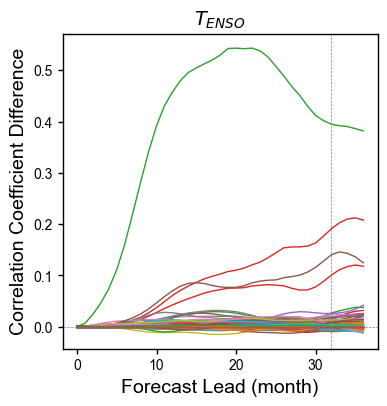

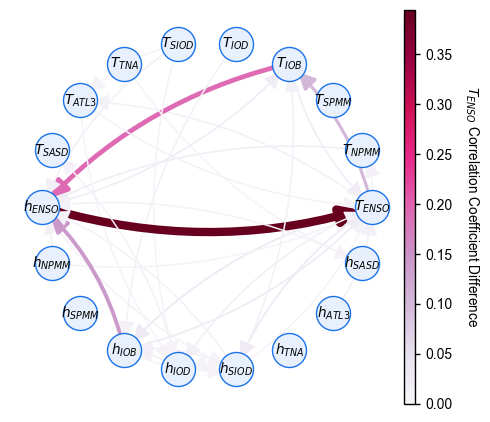

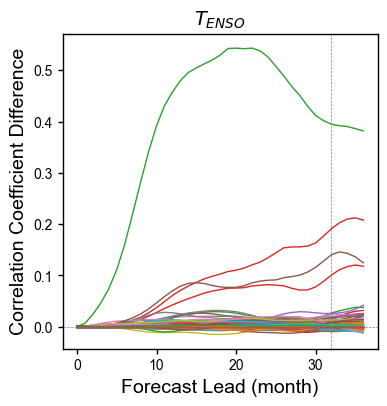

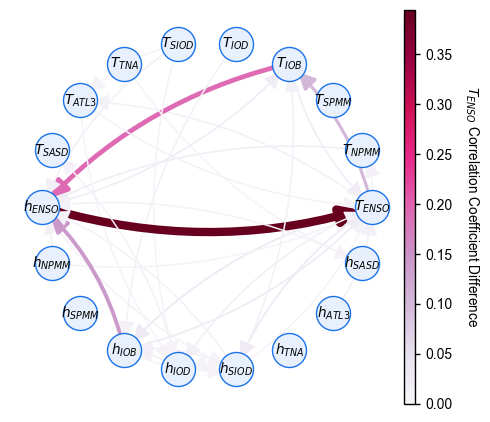

In [10]:
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from tqdm import tqdm
from nd2py.utils.plot import get_fig

var_map = {'x': 'T', 'h': 'h'}

loader = []
for source_var in ['x', 'h']:
    for source_mode in assistant.modes:
        for target_var in ['x', 'h']:
            for target_mode in assistant.modes:
                loader.append((source_var, source_mode, target_var, target_mode))
insample_skills = dict(
    x_ENSO=32, x_NPMM=17, x_SPMM=5,
    x_IOB=29, x_IOD=13, x_SIOD=19,
    x_TNA=10, x_ATL3=5, x_SASD=5,
    h_ENSO=24, h_NPMM=23, h_SPMM=20,
    h_IOB=33, h_IOD=24, h_SIOD=29,
    h_TNA=15, h_ATL3=6, h_SASD=15,
)
# for var in ['x', 'h']:
    # for mode in assistant.modes:
for var in ['x']:
    for mode in ['ENSO']:
        if True: # Correlation Difference
            fi, fig, axes = get_fig(1, 1, AW=8, AH=8, dpi=100, fontsize=14, lw=1, LM=5, RM=5, TM=5, BM=5)
            ax = axes[0]
            improvement = {}
            for source_var, source_mode, target_var, target_mode in loader:
                df1 = PREDICTION
                df2 = PREDICTION_wo_interaction_of_variable_pairs[(source_var, source_mode, target_var, target_mode)]
                stop = df1.index.get_level_values('time') + df1.index.get_level_values('lead')
                true = df1[(var, mode)].swaplevel().loc[0].reindex(stop.values).values
                df_plot1 = (
                    df1[(var, mode)]
                    .to_frame(f'pred')
                    .reset_index()
                    .assign(stop=stop, true=true)
                    .groupby('lead').apply(lambda x: x['pred'].corr(x['true']))
                )
                df_plot2 = (
                    df2[(var, mode)]
                    .to_frame(f'pred')
                    .reset_index()
                    .assign(stop=stop, true=true)
                    .groupby('lead').apply(lambda x: x['pred'].corr(x['true']))
                )
                df_plot = df_plot1 - df_plot2
                ax.plot(df_plot.index, df_plot.values, rasterized=True, label=f'${source_var}_{{{source_mode}}} \\rightarrow {target_var}_{{{target_mode}}}$')
                improvement[(source_var, source_mode, target_var, target_mode)] = df_plot.loc[insample_skills[f'{var}_{mode}']]
            ax.set_title(f'${var_map[var]}_{{{mode}}}$')
            ax.axhline(0, color='gray', linestyle='--', linewidth=0.5)
            ax.axvline(insample_skills[f'{var}_{mode}'], color='gray', linestyle='--', linewidth=0.5)
            ax.set_xlabel('Forecast Lead (month)')
            ax.set_ylabel('Correlation Coefficient Difference')
            display(fig)
        if True: # Network
            cmap = plt.get_cmap('PuRd')
            vmax = max(improvement.values())
            threshold = np.percentile(list(improvement.values()), 90)
            norm = mcolors.Normalize(vmin=0, vmax=vmax)
            G = nx.DiGraph()
            for v in ['x', 'h']:
                for m in assistant.modes:
                    G.add_node(f"${var_map[v]}_{{{m}}}$")
            for (s_var, s_mode, t_var, t_mode), imp in improvement.items():
                if imp < threshold: continue
                u = f"${var_map[s_var]}_{{{s_mode}}}$"
                v = f"${var_map[t_var]}_{{{t_mode}}}$"
                G.add_edge(u, v, weight=imp)
            edges = []
            edge_colors = []
            edge_widths = []
            for u, v, data in G.edges(data=True):
                imp = data['weight']
                edges.append((u, v))
                edge_colors.append('red' if imp < 0 else cmap(norm(imp)))
                width = 1 + 5 * norm(abs(imp))
                edge_widths.append(width)

            fi, fig, axes = get_fig(1, 1, AW=10, AH=10, dpi=100, fontsize=14, lw=1, LM=5, RM=5, TM=5, BM=5)
            ax = axes[0]
            pos = nx.circular_layout(G)
            nx.draw_networkx_nodes(G, pos, ax=ax, node_color='#E8F0FE', edgecolors='#1A73E8', node_size=600)
            nx.draw_networkx_labels(G, pos, ax=ax, font_size=0.7*fi['fontsize'])
            nx.draw_networkx_edges(
                G, pos, 
                ax=ax,
                edgelist=edges,
                edge_color=edge_colors,
                width=edge_widths,
                arrowsize=25, 
                arrowstyle='-|>',
                connectionstyle="arc3,rad=0.15"
            )
            sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
            sm.set_array([])
            x, y, w, h = ax.get_position().bounds
            cax = fig.add_axes([x + w, y, 0.02, h])
            cbar = plt.colorbar(sm, cax=cax, shrink=0.6)
            cbar.set_label(f'${var_map[var]}_{{{mode}}}$ Correlation Coefficient Difference', rotation=270, labelpad=20, fontsize=0.7*fi['fontsize'])
            ax.axis('off')
            ax.axis('equal')

            fig.savefig(save_path / f"Fig3d.png", dpi=300, transparent=True)
            fig.savefig(save_path / f"Fig3d.pdf", dpi=300, transparent=True)
            fig.savefig(save_path / f"Fig3d.svg", dpi=300, transparent=True)
            display(fig)

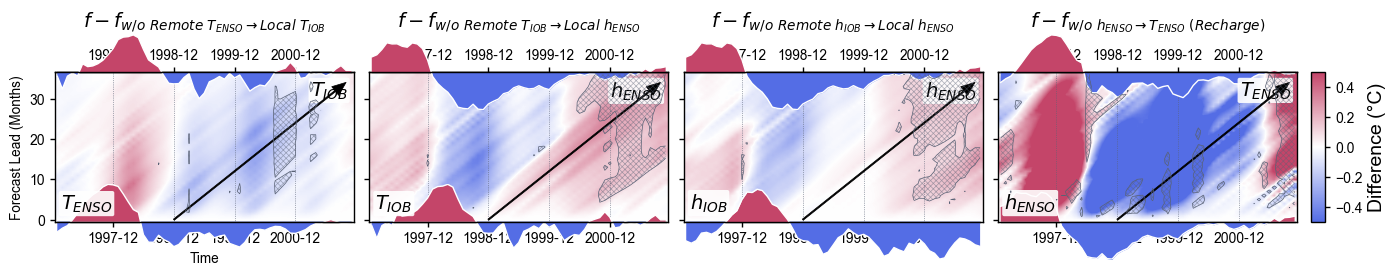

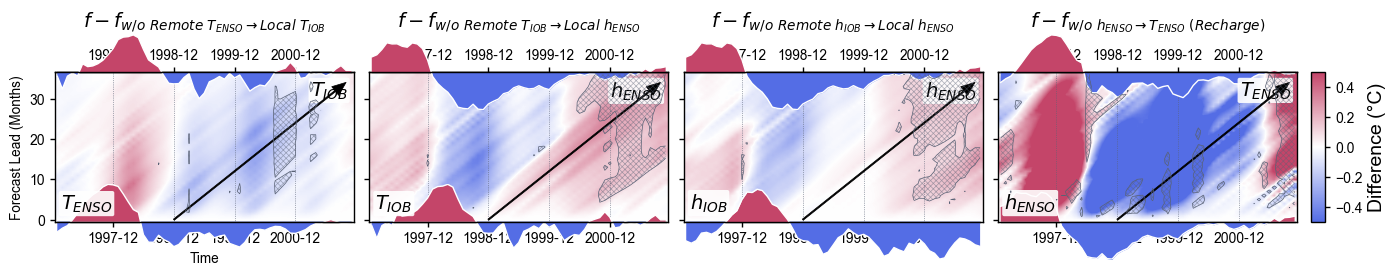

In [11]:
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from tqdm import tqdm
from nd2py.utils.plot import get_fig

fi, fig, axes = get_fig(
    1, 4, FW=36, A_ratio=2.0, LM=3, RM=6, TM=3, BM=5, VS=0.8, HS=0.8, 
    dpi=100, fontsize=14, lw=1, sharex=True, sharey=True
)
ax_loader = iter(axes.reshape(4, 1).T.ravel())
var_map = {'x': 'T', 'h': 'h'}

for config in [
    {'source': ('x', 'ENSO'), 'target': ('x', 'IOB'), 'title': '$f - f_{w/o~Remote~T_{ENSO} \\rightarrow Local~T_{IOB}}$'},
    {'source': ('x', 'IOB'), 'target': ('h', 'ENSO'), 'title': '$f - f_{w/o~Remote~T_{IOB} \\rightarrow Local~h_{ENSO}}$'},
    {'source': ('h', 'IOB'), 'target': ('h', 'ENSO'), 'title': '$f - f_{w/o~Remote~h_{IOB} \\rightarrow Local~h_{ENSO}}$'},
    {'source': ('h', 'ENSO'), 'target': ('x', 'ENSO'), 'title': '$f - f_{w/o~h_{ENSO} \\rightarrow T_{ENSO}~(Recharge)}$'},
]:
    var, mode = config['target']
    source_var, source_mode = config['source']
    title = config['title']
    df1 = PREDICTION # .loc['1997-01':'2001-11']
    df2 = PREDICTION_wo_interaction_of_variable_pairs[(source_var, source_mode, var, mode)] # .loc['1997-01':'2001-11']
    ax = next(ax_loader)
    if True: # Tempreture Difference
        start = df1.index.get_level_values('time')
        stop = df1.index.get_level_values('time') + df1.index.get_level_values('lead')
        df_plot = (
            (df1 - df2)[(var, mode)]
            .to_frame(f'{var}_{mode}')
            .reset_index()
            .assign(stop=stop)
            .pipe(lambda x: x[x['stop'].between('1997-01', '2001-11')])
            .pivot_table(index='lead', columns='stop', values=f'{var}_{mode}')
        )
        norm = plt.Normalize(vmin=-0.5, vmax=0.5)
        cmap = mcolors.LinearSegmentedColormap.from_list('custom_rdbu', ['#546de5', '#ffffff', '#c44569'])
        im = ax.imshow(
            df_plot.values, interpolation='bilinear', aspect='auto', 
            rasterized=True, norm=norm, cmap=cmap, origin='lower'
        )
    if True: # MAE Difference
        mae_threshold = 0.1 # 摄氏度
        df_tmp1 = (
            df1[(var, mode)]
            .to_frame(f'{var}_{mode}')
            .reset_index()
            .assign(stop=stop)
            .pipe(lambda x: x[x['stop'].between('1997-01', '2001-11')])
            .pivot_table(index='lead', columns='stop', values=f'{var}_{mode}')
        )
        MAE1 = np.abs(df_tmp1 - df_tmp1.loc[[0]].values)
        df_tmp2 = (
            df2[(var, mode)]
            .to_frame(f'{var}_{mode}')
            .reset_index()
            .assign(stop=stop)
            .pipe(lambda x: x[x['stop'].between('1997-01', '2001-11')])
            .pivot_table(index='lead', columns='stop', values=f'{var}_{mode}')
        )
        MAE2 = np.abs(df_tmp2 - df_tmp2.loc[[0]].values)
        df_plot2 = (MAE1 - MAE2)
        X, Y = np.meshgrid(np.arange(df_plot2.shape[1]), np.arange(df_plot2.shape[0]))
        with plt.rc_context({'hatch.color': '#59627580', 'hatch.linewidth': 0.5}):
            cf = ax.contourf(X, Y, df_plot2.values, levels=[mae_threshold, 999], hatches=['xxxxxx'], colors='none', zorder=10000)
        ct = ax.contour(X, Y, df_plot2.values, levels=[mae_threshold], colors='#596275', linewidths=0.5, zorder=10000)
        cf.set_rasterized(True)
        ct.set_rasterized(True)
    if True: # Invalid Area
        rows, cols = df_plot.shape
        X, Y = np.meshgrid(np.arange(cols), np.arange(rows))
        with plt.rc_context({'hatch.color': '#dfe6e9'}):
            cf = ax.contourf(X, Y, np.isnan(df_plot.values), levels=[0.5, 1.5], hatches=['////'], colors='none', zorder=0)
        cf.set_rasterized(True)
    if True: # Labels
        RN, CN = 1, 4
        idx = axes.tolist().index(ax)
        i, j = idx // CN, idx % CN

        ax.text(
            0.98, 0.95, f'${var_map[var]}_{{{mode}}}$', 
            ha='right', va='top', fontsize=fi['fontsize'], transform=ax.transAxes, zorder=9999,
            bbox=dict( facecolor='white', alpha=0.9, boxstyle='round,pad=0.1', edgecolor='none' ),
        )
        ax.text(
            0.02, 0.05, f'${var_map[source_var]}_{{{source_mode}}}$', 
            ha='left', va='bottom', fontsize=fi['fontsize'], transform=ax.transAxes, zorder=9999,
            bbox=dict( facecolor='white', alpha=0.9, boxstyle='round,pad=0.1', edgecolor='none' ),
        )
        # ax.plot([0, 24], [0, 24], color='black', lw=0.5, zorder=9999)
        # ax.arrow(0, 0, 24, 24, color='black', lw=0.5, head_width=5, head_length=10, length_includes_head=True, zorder=9999)
        ax.annotate(
            '', 
            xy=(34+23, 34),      # 箭头尖端 (终点)
            xytext=(23, 0),    # 箭头尾部 (起点)
            arrowprops=dict(
                facecolor='black', 
                edgecolor='black',
                linewidth=0.5,
                width=1,          # 箭杆宽度 (points)
                headwidth=8,      # 箭头底部宽度 (points)
                headlength=10,     # 箭头长度 (points)
                shrinkA=0,        # 缩进设置，0表示紧贴起点
                shrinkB=0         # 0表示紧贴终点
            ),
            zorder=9999
        )
        if (i == RN // 2 and j == 0):
            ax.set_ylabel('Forecast Lead (Months)', fontsize=0.7*fi['fontsize'])
        else:
            ax.set_ylabel('')
        if (i == RN - 1 and j == 0):
            ax.set_xlabel('Time', fontsize=0.7*fi['fontsize'])
        else:
            ax.set_xlabel('')
        # if (i == 0 and j == (CN - 1) // 2):
        ax.set_title(title, fontsize=fi['fontsize'])
        if (i == RN - 1):
            ax.set_xticks(np.arange(df_plot.shape[1]))
            ax.set_xticklabels(df_plot.columns, rotation=0)
            ax.set_xticks(ax.get_xticks()[11::12])
        if (i == 0):
            secax = ax.secondary_xaxis('top')
            secax.set_xticks(np.arange(df_plot.shape[1]))
            secax.set_xticklabels(df_plot.columns, rotation=0, fontsize=0.7*fi['fontsize'], fontfamily='Arial')
            secax.set_xticks(secax.get_xticks()[11::12])
            # secax.set_xlabel('Target Time', fontsize=0.7*fi['fontsize'], fontfamily='Arial')
        if (0 < i < RN - 1):
            ax.xaxis.set_visible(False)
        ax.grid('on', color='#596275', linestyle=':', linewidth=0.5, which='major', zorder=999, axis='x')
    if True: # Time Series of Index (Lower - Source)
        x = np.arange(cols)
        y = (
            df1[(source_var, source_mode)]
            .to_frame(f'{source_var}_{source_mode}')
            .reset_index()
            .assign(stop=stop)
            .pipe(lambda x: x[x['stop'].between('1997-01', '2001-11')])
            .pivot_table(index='lead', columns='stop', values=f'{source_var}_{source_mode}')
            .loc[0]
        )
        total_height = 0.5
        ax_bottom = ax.inset_axes([0, -total_height/2, 1, total_height])
        ax_bottom.fill_between(x, y, 0, where=(y > 0), color='#c44569', interpolate=True, lw=0)
        ax_bottom.fill_between(x, y, 0, where=(y <= 0), color='#546de5', interpolate=True, lw=0)
        ax_bottom.plot(x, y, color='white', lw=1)
        ax_bottom.plot(x, 0*y, color='black', lw=1)
        ax_bottom.set_ylim(-np.max(np.abs(y)) , np.max(np.abs(y)) )
        ax_bottom.set_xlim(ax.get_xlim())
        ax_bottom.axis('off')
    if True: # Time Series of Index (Upper - Target)
        x = np.arange(cols)
        y = (
            df1[(var, mode)]
            .to_frame(f'{var}_{mode}')
            .reset_index()
            .assign(stop=stop)
            .pipe(lambda x: x[x['stop'].between('1997-01', '2001-11')])
            .pivot_table(index='lead', columns='stop', values=f'{var}_{mode}')
            .loc[0]
        )
        total_height = 0.5
        ax_top = ax.inset_axes([0, 1-total_height/2, 1, total_height])
        ax_top.fill_between(x, y, 0, where=(y > 0), color='#c44569', interpolate=True, lw=0)
        ax_top.fill_between(x, y, 0, where=(y <= 0), color='#546de5', interpolate=True, lw=0)
        ax_top.plot(x, y, color='white', lw=1)
        ax_top.plot(x, 0*y, color='black', lw=1)
        ax_top.set_ylim(-np.max(np.abs(y)) , np.max(np.abs(y)) )
        ax_top.set_xlim(ax.get_xlim())
        ax_top.axis('off')

# fig.suptitle(title, fontsize=fi['fontsize'])
x, y, w, h = fi['right_box']
cax = fig.add_axes([x+0.01, y, 0.01, h])
plt.colorbar(im, cax=cax)
cax.set_ylabel(f'Difference (°C)')

fig.savefig(save_path / 'Fig3e.png', dpi=300, transparent=True)
fig.savefig(save_path / 'Fig3e.pdf', dpi=300, transparent=True)
fig.savefig(save_path / 'Fig3e.svg', dpi=300, transparent=True)
display(fig)